# 03 - Jointures, agrégations, analyse temporelle et graphiques

In [1]:
from pathlib import Path
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

P = Path("../data/processed")
Path("../figures").mkdir(exist_ok=True)
commandes = pd.read_csv(P / "commandes_propre.csv", parse_dates=[
    "order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date",
    "order_delivered_customer_date", "order_estimated_delivery_date"])
articles = pd.read_csv(P / "articles_propre.csv", parse_dates=["shipping_limit_date"])
produits = pd.read_csv(P / "produits_propre.csv")
clients = pd.read_csv(P / "clients_propre.csv", dtype={"customer_zip_code_prefix": str})
sns.set_theme(style="whitegrid")

## Jointures avec contrôle du nombre de lignes

In [2]:
nb_articles = len(articles)
ventes = articles.merge(produits[["product_id", "product_category_name_english"]],
                        on="product_id", how="left", validate="many_to_one")
ventes = ventes.merge(commandes[["order_id", "customer_id", "order_status", "order_purchase_timestamp"]],
                      on="order_id", how="left", validate="many_to_one")
ventes = ventes.merge(clients[["customer_id", "customer_state"]],
                      on="customer_id", how="left", validate="many_to_one")
assert len(ventes) == nb_articles
print(nb_articles, "->", len(ventes))

nb_commandes = len(commandes)
commandes_clients = commandes.merge(clients[["customer_id", "customer_state"]],
                                    on="customer_id", how="left", validate="many_to_one")
assert len(commandes_clients) == nb_commandes
print(nb_commandes, "->", len(commandes_clients))

112650 -> 112650


99441 -> 99441


## Q1 - Chiffre d'affaires par catégorie

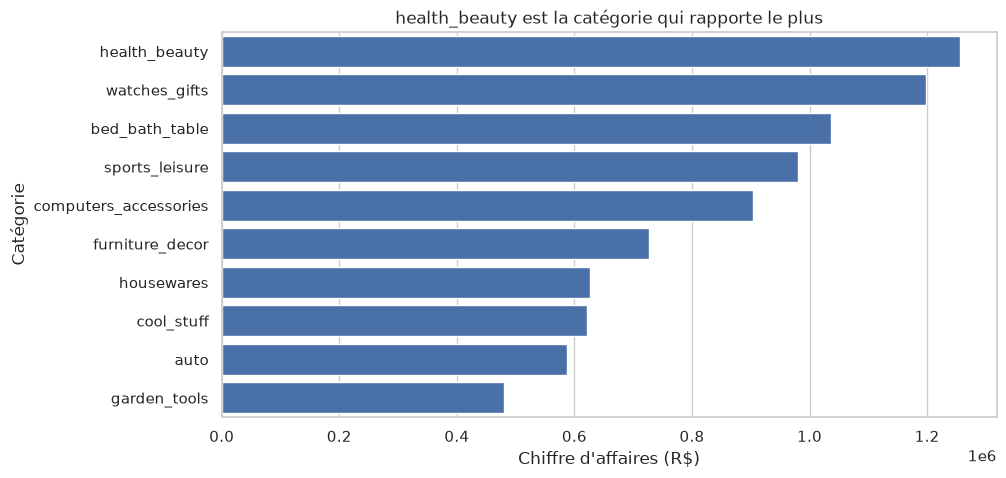

product_category_name_english
health_beauty            1255695.13
watches_gifts            1198185.21
bed_bath_table           1035964.06
sports_leisure            979740.92
computers_accessories     904322.02
furniture_decor           727465.05
housewares                626825.80
cool_stuff                620835.39
auto                      586620.73
garden_tools              481009.94
Name: price, dtype: float64

In [3]:
ventes_ok = ventes[ventes["order_status"] != "canceled"]
ca_categorie = (ventes_ok.groupby("product_category_name_english")["price"]
                .sum().sort_values(ascending=False).head(10))
fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(x=ca_categorie.values, y=ca_categorie.index, ax=ax, color="#3b6fb6")
ax.set_title(f"{ca_categorie.index[0]} est la catégorie qui rapporte le plus")
ax.set_xlabel("Chiffre d'affaires (R$)")
ax.set_ylabel("Catégorie")
fig.savefig("../figures/ca_categorie.png", dpi=150, bbox_inches="tight")
plt.show()
ca_categorie

**Conclusion Q1 :** (**Conclusion Q1 :** La catégorie **health_beauty** génère le plus de chiffre d'affaires, avec environ 1,26 million de R$ (hors commandes annulées). Elle devance de peu **watches_gifts** (1,20 million), puis **bed_bath_table** (1,04 million), **sports_leisure** (0,98 million) et **computers_accessories** (0,90 million). Entre la première et la dixième catégorie (garden_tools, 0,48 million), le chiffre d'affaires est divisé par environ 2,6. Les cinq premières catégories pèsent à elles seules près de 64 % du chiffre d'affaires des dix premières, donc les ventes sont concentrées sur quelques catégories.)

## Q2 - Évolution mensuelle (analyse temporelle)

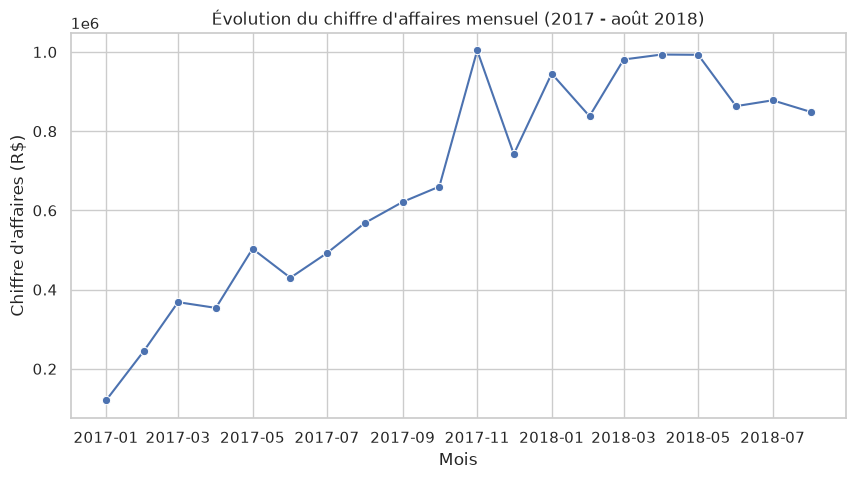

order_purchase_timestamp
2017-01-01     NaN
2017-02-01    1.04
2017-03-01    0.50
2017-04-01   -0.04
2017-05-01    0.42
2017-06-01   -0.15
2017-07-01    0.15
2017-08-01    0.15
2017-09-01    0.09
2017-10-01    0.06
2017-11-01    0.52
2017-12-01   -0.26
2018-01-01    0.27
2018-02-01   -0.11
2018-03-01    0.17
2018-04-01    0.01
2018-05-01   -0.00
2018-06-01   -0.13
2018-07-01    0.02
2018-08-01   -0.03
Freq: MS, Name: price, dtype: float64

In [4]:
ca_mensuel = (ventes_ok.set_index("order_purchase_timestamp")
              .resample("MS")["price"].sum())
ca_mensuel = ca_mensuel["2017-01-01":"2018-08-01"]
fig, ax = plt.subplots(figsize=(10, 5))
sns.lineplot(x=ca_mensuel.index, y=ca_mensuel.values, marker="o", ax=ax)
ax.set_title("Évolution du chiffre d'affaires mensuel (2017 - août 2018)")
ax.set_xlabel("Mois")
ax.set_ylabel("Chiffre d'affaires (R$)")
fig.savefig("../figures/ca_mensuel.png", dpi=150, bbox_inches="tight")
plt.show()
ca_mensuel.pct_change().round(2)

**Conclusion Q2 :** (**Conclusion Q2 :** Le chiffre d'affaires mensuel progresse fortement sur la période : il passe d'environ 0,12 million de R$ en janvier 2017 à environ 0,85 million en août 2018, soit environ 7 fois plus. La hausse est nette en 2017 (+104 % entre janvier et février, +50 % en mars, +52 % en novembre). Le pic est atteint en **novembre 2017** (environ 1,0 million de R$), puis le chiffre d'affaires recule de 26 % en décembre. En 2018, il se stabilise autour de 0,85 à 1,0 million par mois, avec une légère baisse à partir de juin. Les mois incomplets de 2016 et de fin 2018 sont exclus de cette courbe.)

## Q3 - Commandes par État

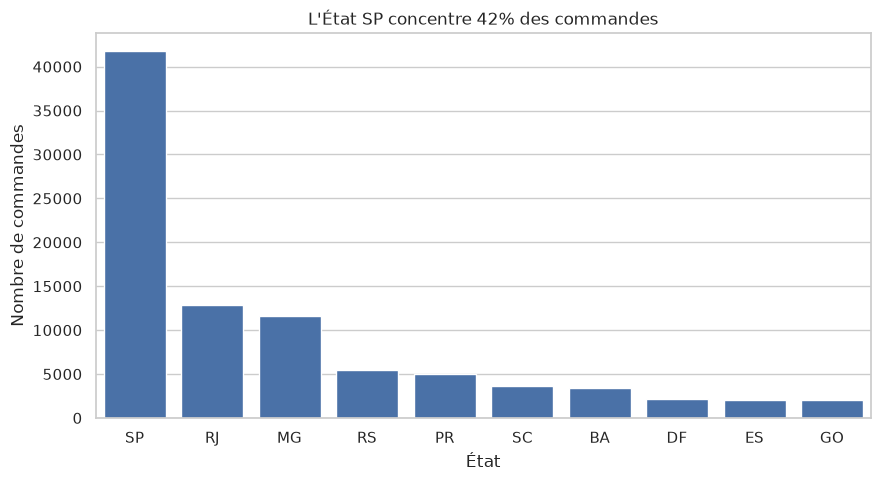

In [5]:
par_etat = (commandes_clients.groupby("customer_state", observed=True)["order_id"]
            .nunique().sort_values(ascending=False).head(10))
fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(x=par_etat.index.astype(str), y=par_etat.values, ax=ax, color="#3b6fb6")
ax.set_title(f"L'État {par_etat.index[0]} concentre {par_etat.iloc[0] / commandes_clients['order_id'].nunique():.0%} des commandes")
ax.set_xlabel("État")
ax.set_ylabel("Nombre de commandes")
fig.savefig("../figures/commandes_etat.png", dpi=150, bbox_inches="tight")
plt.show()

**Conclusion Q3 :** (**Conclusion Q3 :** L'État de **São Paulo (SP)** concentre 42 % des commandes, soit environ 41 500 commandes. Il est loin devant **Rio de Janeiro (RJ)** (environ 12 800 commandes) et **Minas Gerais (MG)** (environ 11 500). Ces trois États réunissent à eux seuls environ deux tiers des commandes. Les autres États du top 10 (RS, PR, SC, BA, DF, ES, GO) restent sous les 5 500 commandes chacun. Les commandes sont donc très concentrées dans le sud-est du Brésil.)

## Q4 - Retards de livraison

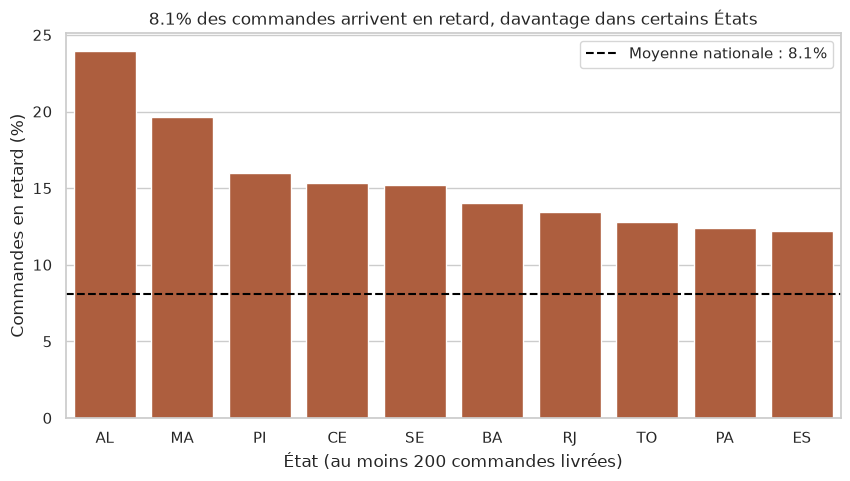

In [6]:
livrees = commandes_clients[commandes_clients["order_status"] == "delivered"].dropna(
    subset=["order_delivered_customer_date"]).copy()
livrees["en_retard"] = livrees["order_delivered_customer_date"] > livrees["order_estimated_delivery_date"]
taux_global = livrees["en_retard"].mean()
retard_etat = (livrees.groupby("customer_state", observed=True)["en_retard"]
               .agg(["mean", "size"]).query("size >= 200")
               .sort_values("mean", ascending=False).head(10))
fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(x=retard_etat.index.astype(str), y=retard_etat["mean"] * 100, ax=ax, color="#c0562b")
ax.axhline(taux_global * 100, color="black", linestyle="--", label=f"Moyenne nationale : {taux_global:.1%}")
ax.set_title(f"{taux_global:.1%} des commandes arrivent en retard, davantage dans certains États")
ax.set_xlabel("État (au moins 200 commandes livrées)")
ax.set_ylabel("Commandes en retard (%)")
ax.legend()
fig.savefig("../figures/retards_etat.png", dpi=150, bbox_inches="tight")
plt.show()

**Conclusion Q4 :** (**Conclusion Q4 :** **8,1 %** des commandes livrées arrivent après la date estimée. Ce taux cache de fortes différences entre États : **Alagoas (AL)** atteint environ 24 %, soit trois fois la moyenne nationale, devant **Maranhão (MA)** (environ 20 %), **Piauí (PI)** (environ 16 %), **Ceará (CE)** et **Sergipe (SE)** (environ 15 %). Ces États sont en grande majorité situés dans le nord-est du pays, plus éloigné des zones où se concentrent les commandes. Tous les États du classement dépassent la moyenne nationale. Seuls les États avec au moins 200 commandes livrées sont retenus.)

## Q5 - Prix et frais de port

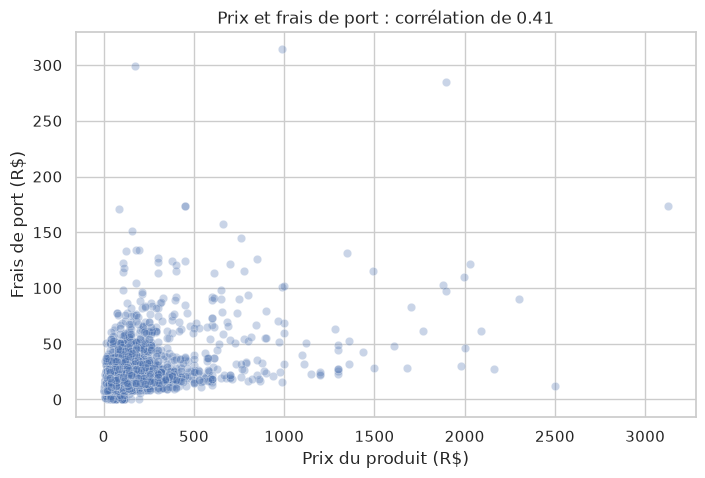

In [7]:
echantillon = ventes_ok.sample(5000, random_state=0)
fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(data=echantillon, x="price", y="freight_value", alpha=0.3, ax=ax)
corr = ventes_ok[["price", "freight_value"]].corr().iloc[0, 1]
ax.set_title(f"Prix et frais de port : corrélation de {corr:.2f}")
ax.set_xlabel("Prix du produit (R$)")
ax.set_ylabel("Frais de port (R$)")
fig.savefig("../figures/prix_frais_port.png", dpi=150, bbox_inches="tight")
plt.show()

**Conclusion Q5 :** (**Conclusion Q5 :** La corrélation entre le prix du produit et ses frais de port est de **0,41**, un lien positif mais **modéré**. Les produits chers ont en moyenne des frais de port plus élevés, mais la dispersion est grande : la plupart des articles coûtent moins de 500 R$ avec des frais de port inférieurs à 100 R$, et on voit des produits à plus de 1 000 R$ avec des frais faibles. Le prix n'explique donc qu'une partie des frais de port : le poids, le volume et la distance de livraison jouent sans doute un rôle important, mais cette analyse ne permet pas de le démontrer.)

## Graphique bonus - Délai de livraison

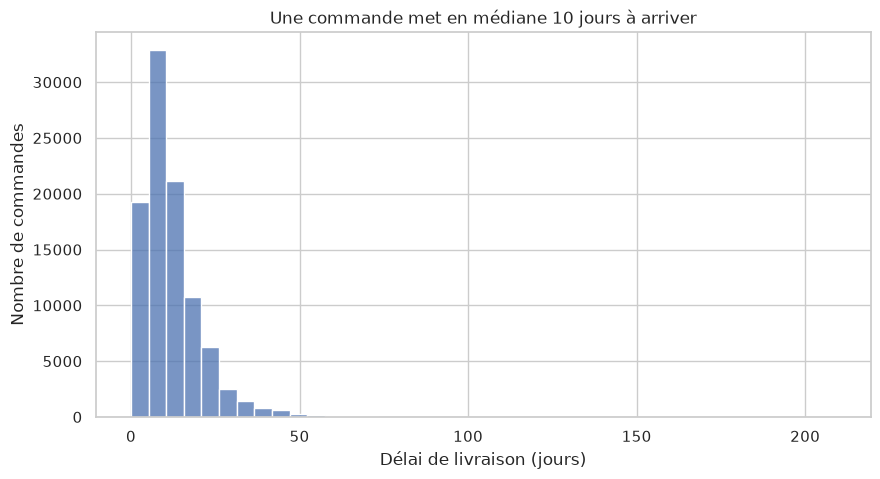

In [8]:
livrees["jours_livraison"] = (livrees["order_delivered_customer_date"] - livrees["order_purchase_timestamp"]).dt.days
fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(livrees["jours_livraison"], bins=40, ax=ax)
ax.set_title(f"Une commande met en médiane {livrees['jours_livraison'].median():.0f} jours à arriver")
ax.set_xlabel("Délai de livraison (jours)")
ax.set_ylabel("Nombre de commandes")
fig.savefig("../figures/delai_livraison.png", dpi=150, bbox_inches="tight")
plt.show()

## Tableau croisé

In [9]:
top_cat = ca_categorie.index[:5]
pd.pivot_table(ventes_ok[ventes_ok["product_category_name_english"].isin(top_cat)],
               values="price", index="product_category_name_english",
               columns="customer_state", aggfunc="sum").fillna(0).round(0).iloc[:, :8]

customer_state,AC,AL,AM,AP,BA,CE,DF,ES
product_category_name_english,,,,,,,,
bed_bath_table,568.0,2023.0,681.0,670.0,25695.0,7021.0,16391.0,22679.0
computers_accessories,1290.0,7714.0,1961.0,2150.0,33495.0,12218.0,24129.0,14491.0
health_beauty,1387.0,12780.0,2776.0,1381.0,51218.0,32419.0,29863.0,20214.0
sports_leisure,1677.0,3748.0,1363.0,813.0,38245.0,10552.0,22706.0,20086.0
watches_gifts,1390.0,11683.0,1811.0,1640.0,48821.0,29285.0,32730.0,29461.0


## Conclusions
Q1 :health_beauty est la catégorie qui rapporte le plus (environ 1,26 million de R$), devant watches_gifts et bed_bath_table.
Q2 :le chiffre d'affaires mensuel est multiplié par environ 7 entre janvier 2017 et août 2018, avec un pic en novembre 2017.
Q3 : São Paulo concentre 42 % des commandes ; SP, RJ et MG en réunissent environ deux tiers.
Q4 :8,1 % des commandes arrivent en retard, jusqu'à environ 24 % dans l'État d'Alagoas.
Q5 :le prix et les frais de port sont modérément corrélés (0,41).

## Limites
- Les données couvrent 2016 à 2018 seulement.
- Il n'y a pas de coût d'achat, donc pas de calcul de marge.
- Les commandes annulées sont exclues des questions 1 et 2.
- Le chiffre d'affaires est le prix des produits, hors frais de port.
- Les États du classement des retards sont limités à ceux ayant au moins 200 commandes livrées.
- Une corrélation ne prouve pas une cause (Q5).
- Les valeurs lues sur les graphiques sont approximatives ; les valeurs exactes sont dans les tableaux des cellules.